<a href="https://colab.research.google.com/github/m4tss0/Calculo-Numerico-2026-2/blob/main/Atividade_Erro_de_Interpola%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade - Erros de Interpolação
Nome: Mateus de Lima Alencar Soares


RA: 185301


Turma: Noturno

## Preparação do ambiente


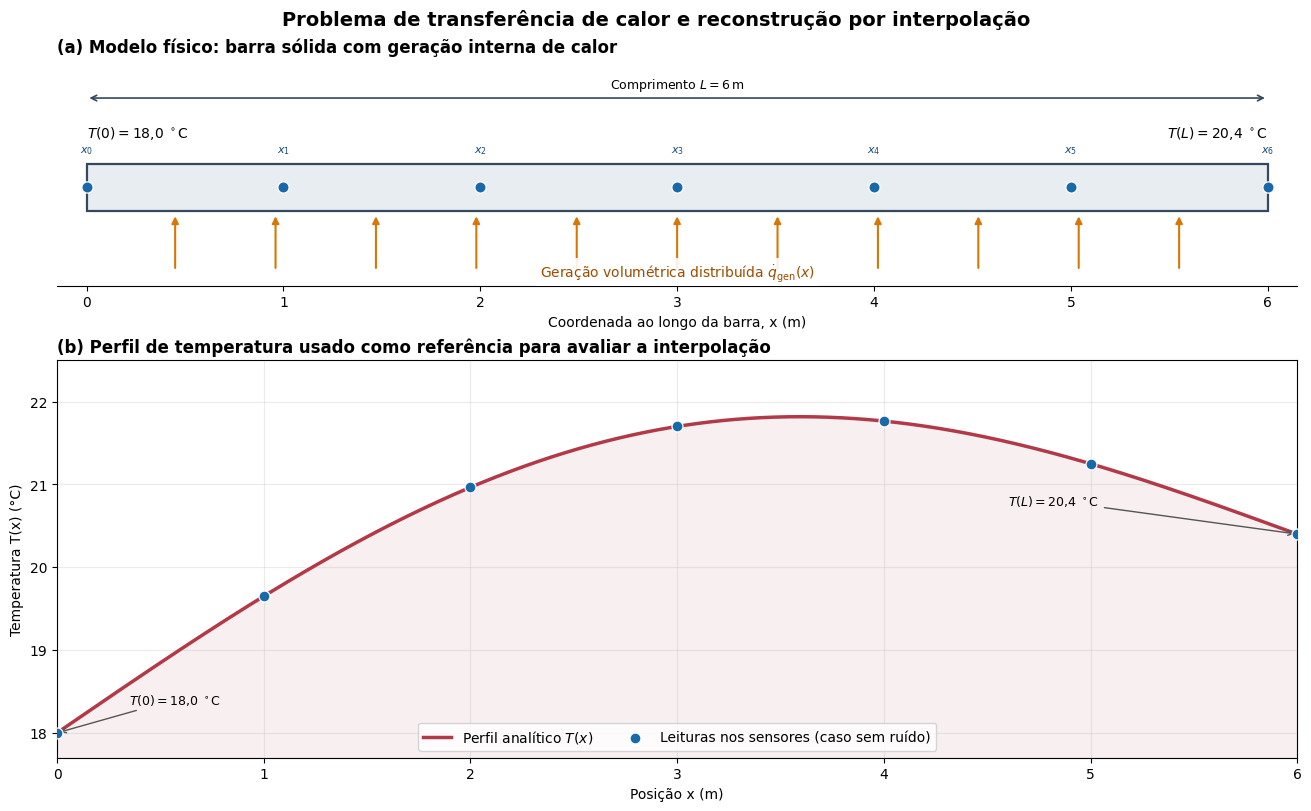

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [3]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

In [4]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


In [5]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 - Interpolação (Dados Exatos)


--- Métricas de Erro para 7 sensores exatos ---


,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


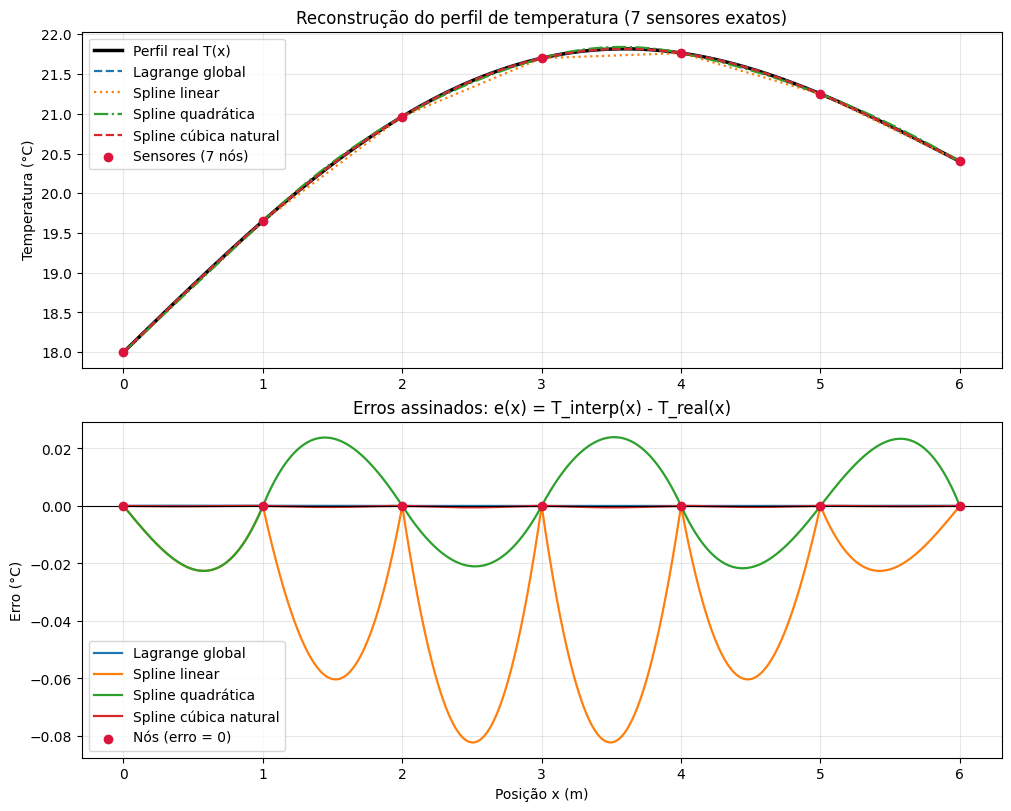

In [6]:
# ==============================================================================
# PARÂMETROS CONFIGURÁVEIS (Altere aqui caso queira testar outros cenários)
# ==============================================================================
NUM_SENSORES = 7                   # Quantidade de sensores na barra
funcao_perfil = temperatura_real   # Função de referência (definida no notebook)
malha_avaliacao = x_fino           # Malha densa para cálculo dos erros
valores_reais = T_fino             # Temperatura exata na malha densa

# ==============================================================================
# 1. GERAÇÃO DOS NÓS E CONSTRUÇÃO DOS INTERPOLADORES
# ==============================================================================
# Cria posições igualmente espaçadas entre x_min (0) e x_max (L)
x_sensores = np.linspace(x_min, x_max, NUM_SENSORES)
y_sensores = funcao_perfil(x_sensores)

# Instancia os 4 métodos (Lagrange, Spline Linear, Quadrática e Cúbica)
metodos = criar_metodos(x_sensores, y_sensores)

# ==============================================================================
# 2. CÁLCULO E EXIBIÇÃO DAS MÉTRICAS DE ERRO (E_max, MAE, RMSE)
# ==============================================================================
tabela_metricas = calcular_metricas(metodos, malha_avaliacao, valores_reais)
print(f"--- Métricas de Erro para {NUM_SENSORES} sensores exatos ---")
display(tabela_metricas)

# ==============================================================================
# 3. VISUALIZAÇÃO GRÁFICA (Curvas Reconstruídas e Erros Assinados)
# ==============================================================================
fig, axes = plt.subplots(2, 1, figsize=(10, 8), constrained_layout=True)

# Dicionário de estilos visuais para facilitar a leitura das curvas sobrepostas
estilos_linha = {
    "Lagrange global": "--",
    "Spline linear": ":",
    "Spline quadrática": "-.",
    "Spline cúbica natural": "--"
}

# --- Painel Superior: Perfil Real vs. Interpoladores ---
axes[0].plot(malha_avaliacao, valores_reais, "k-", linewidth=2.5, label="Perfil real T(x)")
for nome_metodo, interpolador in metodos.items():
    estilo = estilos_linha.get(nome_metodo, "-")  # Usa '-' se você adicionar método novo
    axes[0].plot(malha_avaliacao, interpolador(malha_avaliacao), linestyle=estilo, linewidth=1.6, label=nome_metodo)

axes[0].scatter(x_sensores, y_sensores, color="crimson", zorder=5, label=f"Sensores ({NUM_SENSORES} nós)")
axes[0].set_title(f"Reconstrução do perfil de temperatura ({NUM_SENSORES} sensores exatos)")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# --- Painel Inferior: Erro Assinado e(x) = T_interp(x) - T_real(x) ---
for nome_metodo, interpolador in metodos.items():
    erro_assinado = interpolador(malha_avaliacao) - valores_reais
    axes[1].plot(malha_avaliacao, erro_assinado, linewidth=1.6, label=nome_metodo)

axes[1].axhline(0, color="black", linestyle="-", linewidth=0.8)
axes[1].scatter(x_sensores, np.zeros_like(x_sensores), color="crimson", zorder=5, label="Nós (erro = 0)")
axes[1].set_title("Erros assinados: e(x) = T_interp(x) - T_real(x)")
axes[1].set_xlabel("Posição x (m)")
axes[1].set_ylabel("Erro (°C)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.show()

## Etapa 2 - Posição e Número dos Sensores

In [10]:
# ==============================================================================
# DEFINIÇÃO DOS NÓS DE CHEBYSHEV-LOBATTO (Original do notebook)
# ==============================================================================
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k * np.pi / (N - 1))
    return np.sort((a + b) / 2 + (b - a) * z / 2)

# ==============================================================================
# PARÂMETROS CONFIGURÁVEIS
# ==============================================================================
LISTA_N = [5, 9, 13, 17]           # Quantidades de nós a serem testadas
funcao_perfil = temperatura_real
malha_avaliacao = x_fino
valores_reais = T_fino

# ==============================================================================
# EXECUÇÃO DA COMPARAÇÃO (Lagrange Equiespaçado vs. Chebyshev-Lobatto)
# ==============================================================================
resultados_etapa2 = []

for N in LISTA_N:
    # Caso A: Distribuição uniforme (equiespaçada)
    x_eq = np.linspace(x_min, x_max, N)
    lag_eq = BarycentricInterpolator(x_eq, funcao_perfil(x_eq))
    erro_eq = lag_eq(malha_avaliacao) - valores_reais

    # Caso B: Distribuição de Chebyshev-Lobatto (concentrada nas bordas)
    x_cheb = nos_chebyshev_lobatto(x_min, x_max, N)
    lag_cheb = BarycentricInterpolator(x_cheb, funcao_perfil(x_cheb))
    erro_cheb = lag_cheb(malha_avaliacao) - valores_reais

    # Armazena as métricas de ambos os casos para o mesmo N
    resultados_etapa2.append({
        "N (sensores)": N,
        "E_max Equiespaçado (°C)": np.max(np.abs(erro_eq)),
        "RMSE Equiespaçado (°C)": np.sqrt(np.mean(erro_eq**2)),
        "E_max Chebyshev (°C)": np.max(np.abs(erro_cheb)),
        "RMSE Chebyshev (°C)": np.sqrt(np.mean(erro_cheb**2))
    })

tabela_nos = pd.DataFrame(resultados_etapa2)
display(tabela_nos)

,N (sensores),E_max Equiespaçado (°C),RMSE Equiespaçado (°C),E_max Chebyshev (°C),RMSE Chebyshev (°C)
0,5,4.530257e-03,2.159567e-03,2.326599e-03,1.532697e-03
1,9,1.043537e-06,3.438146e-07,2.167582e-07,1.202332e-07
2,13,5.908873e-11,1.545245e-11,3.623768e-12,1.931908e-12
3,17,1.989520e-12,2.445428e-13,1.421085e-14,3.836136e-15


## Etapa 3 - Estudo de caso e Decisão técnica

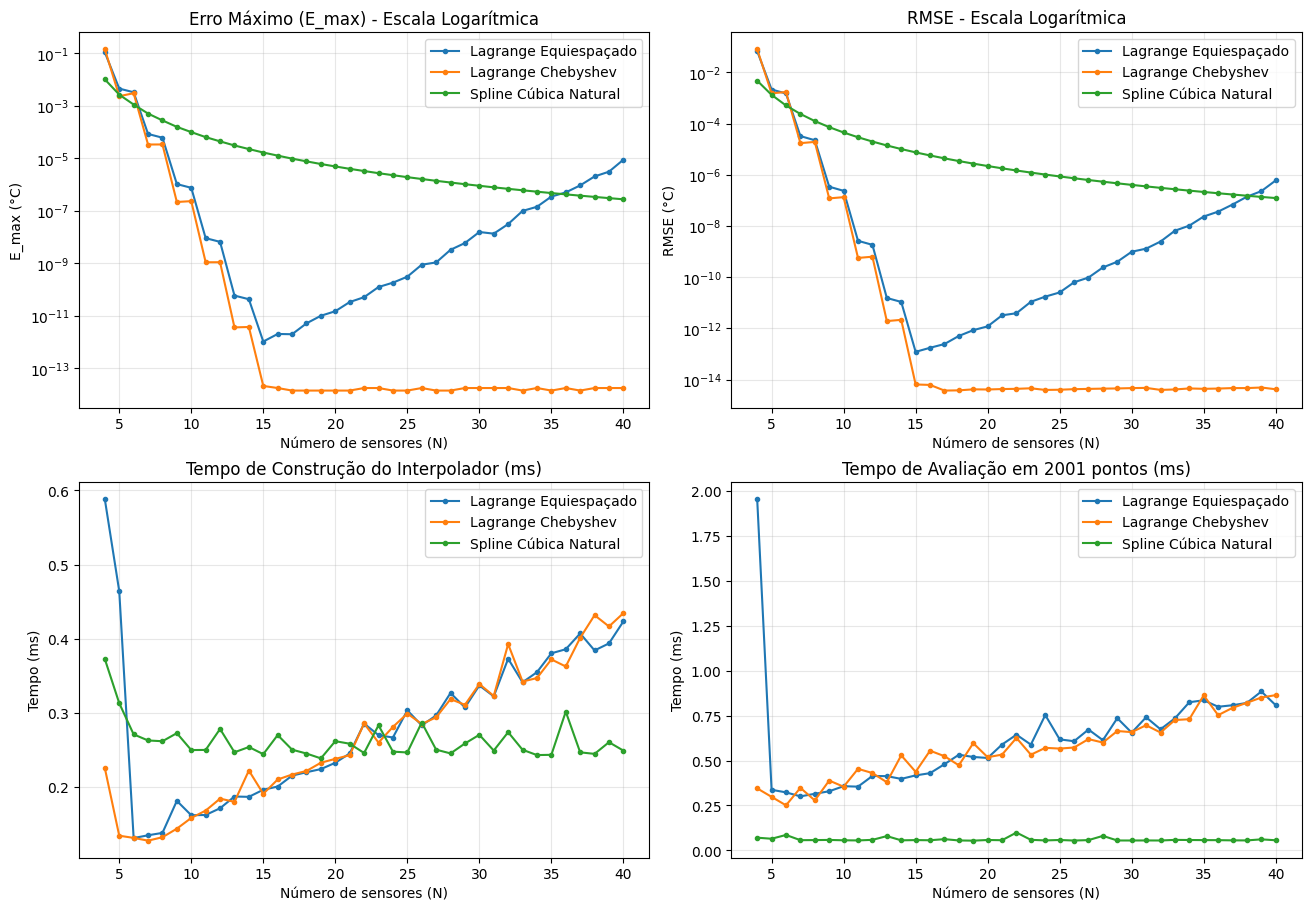

In [11]:
import time

# ==============================================================================
# PARÂMETROS CONFIGURÁVEIS
# ==============================================================================
N_MIN, N_MAX = 4, 40               # Faixa de variação do número de sensores
funcao_perfil = temperatura_real
malha_avaliacao = x_fino
valores_reais = T_fino

# ==============================================================================
# FUNÇÃO AUXILIAR DE MEDIÇÃO (Tempo de construção, avaliação e erros)
# ==============================================================================
def medir_metodo(construtor_fn, x_nos, y_nos, x_eval, y_true):
    """Constrói o interpolador, avalia na malha e retorna erros e tempos em ms."""
    t0 = time.perf_counter()
    modelo = construtor_fn(x_nos, y_nos)
    t1 = time.perf_counter()

    predicao = modelo(x_eval)
    t2 = time.perf_counter()

    erro = predicao - y_true
    return {
        "emax": np.max(np.abs(erro)),
        "rmse": np.sqrt(np.mean(erro**2)),
        "t_const": (t1 - t0) * 1e3,  # Tempo de construção em milissegundos
        "t_eval": (t2 - t1) * 1e3    # Tempo de avaliação em milissegundos
    }

# ==============================================================================
# LOOP PRINCIPAL DE CONVERGÊNCIA
# ==============================================================================
Ns = np.arange(N_MIN, N_MAX + 1)

# Dicionário que armazena o histórico de cada abordagem
historico = {
    "Lagrange Equiespaçado": {"emax": [], "rmse": [], "t_const": [], "t_eval": []},
    "Lagrange Chebyshev":    {"emax": [], "rmse": [], "t_const": [], "t_eval": []},
    "Spline Cúbica Natural": {"emax": [], "rmse": [], "t_const": [], "t_eval": []}
}

for N in Ns:
    # Prepara os nós e medições para o N atual
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = funcao_perfil(x_eq)

    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = funcao_perfil(x_ch)

    # Executa as medições para cada método
    metricas_rodada = {
        "Lagrange Equiespaçado": medir_metodo(BarycentricInterpolator, x_eq, y_eq, malha_avaliacao, valores_reais),
        "Lagrange Chebyshev":    medir_metodo(BarycentricInterpolator, x_ch, y_ch, malha_avaliacao, valores_reais),
        "Spline Cúbica Natural": medir_metodo(lambda x, y: CubicSpline(x, y, bc_type="natural"), x_eq, y_eq, malha_avaliacao, valores_reais)
    }

    # Salva os resultados no histórico
    for nome_metodo, valores in metricas_rodada.items():
        for chave in ["emax", "rmse", "t_const", "t_eval"]:
            historico[nome_metodo][chave].append(valores[chave])

# ==============================================================================
# PLOTAGEM DOS PAINÉIS COMPARATIVOS
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

for nome_metodo, dados in historico.items():
    axes[0, 0].semilogy(Ns, dados["emax"], marker="o", markersize=3, label=nome_metodo)
    axes[0, 1].semilogy(Ns, dados["rmse"], marker="o", markersize=3, label=nome_metodo)
    axes[1, 0].plot(Ns, dados["t_const"], marker="o", markersize=3, label=nome_metodo)
    axes[1, 1].plot(Ns, dados["t_eval"], marker="o", markersize=3, label=nome_metodo)

axes[0, 0].set_title("Erro Máximo (E_max) - Escala Logarítmica")
axes[0, 0].set_ylabel("E_max (°C)")

axes[0, 1].set_title("RMSE - Escala Logarítmica")
axes[0, 1].set_ylabel("RMSE (°C)")

axes[1, 0].set_title("Tempo de Construção do Interpolador (ms)")
axes[1, 0].set_ylabel("Tempo (ms)")

axes[1, 1].set_title(f"Tempo de Avaliação em {len(malha_avaliacao)} pontos (ms)")
axes[1, 1].set_ylabel("Tempo (ms)")

for ax in axes.flat:
    ax.set_xlabel("Número de sensores (N)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.show()

## Etapa 4 - Recomendação Técnica

A seguir são apresentadas 5 recomendações técnicas para a equipe:

1. No caso de poucos sensores exatos, recomenda-se o método do Polinômio Global de Lagrange, especialmente se os sensores estiverem posicionados em nós de Chebyshev-Lobatto ou esquiespaçado. Devido ao perfil térmico suave do aquecimento da barra, este método reconstrói a curva global com RMSE e Emax consideravelmente menores em comparação a splines de baixa ordem.


2. No caso de aumento de sensores, o método deve migrar para a Spline Cúbica, uma vez que polinômios globais de alto grau em posições igualmente espaçadas sofrem amplificação de erros e oscilações nas bordas, e como observado no material gerado nas etapas 1 e 3, a spline mantém a convergência estável, evitando o alto custo de avaliação e o Fenômeno de Runge.


3. Se os sensores apresentarem ruído, não é recomendado o uso da interpolação exata, pois como ela força $T_{\text{interp}}(x_i) = y_i$, ela passa a acompanhar os ruídos aleatórios através da oscilação, o que degrada o RMSE e o Emax nos pontos intermediários. Pode-se utilizar os Splines de Suavização em seu lugar.


4. Ao trabalhar próximo às extermidades analisadas, contente-se ao intervalo de interpolação $[x_{\min}, x_{\max}]$, e evite extrapolações, ou seja estimativa fora dos sensores extremos.


5. Caso não conheça a temperatura verdadeira, não será possível calcular MAE, RSME ou Emax reais entre os sensores, além de impedir que extrapolações. Por tal razão, a validação dos dados deve ser feita por validação cruzada, a qual coonsiste em retirar temporariamente a leitura de um sensor conhecido e verificar o Erro dos sensores vizinhos ao estimar a temperatura naquele ponto.